### Import Library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

### Load Data Manual dan Indobert

In [2]:
MANUAL_PATH = '../../data/labeled/manual_labeling.csv'
INDOBERT_PATH = '../../data/labeled/indobert_labeled.csv'

# manual revisi memakai separator ;
df_manual = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")

# file indobert memakai separator koma
df_indobert = pd.read_csv(INDOBERT_PATH, encoding="utf-8-sig")

df_manual.columns = df_manual.columns.str.strip()
df_indobert.columns = df_indobert.columns.str.strip()

print("Data manual:", df_manual.shape)
print("Data indober:", df_indobert.shape)

print("\nKolom manual:")
print(df_manual.columns.tolist())

print("\nKolom indobert:")
print(df_indobert.columns.tolist())

Data manual: (8790, 2)
Data indober: (48546, 4)

Kolom manual:
['text', 'label']

Kolom indobert:
['text', 'original_text', 'clean_text', 'label_indobert']


### Merapihkan Nama Label

In [3]:
def normalize_label(label):
    label = str(label).strip().lower()

    mapping = {
        "negative": "negative",
        "negatif": "negative",
        "neg": "negative",

        "positive": "positive",
        "positif": "positive",
        "pos": "positive",

        "neutral": "neutral",
        "netral": "neutral",
        "neu": "neutral"
    }

    return mapping.get(label, label)


df_manual["label_manual"] = df_manual["label"].apply(normalize_label)
df_indobert["label_indobert"] = df_indobert["label_indobert"].apply(normalize_label)

print("Distribusi label manual:")
print(df_manual["label_manual"].value_counts())

print("\nDistribusi label indobert:")
print(df_indobert ["label_indobert"].value_counts())

Distribusi label manual:
label_manual
negative    6043
positive    1691
neutral     1056
Name: count, dtype: int64

Distribusi label indobert:
label_indobert
negative    27677
positive    11900
neutral      8969
Name: count, dtype: int64


### Menggabungkan data manual dengan hasil Indobert

Karena file label manual berisi 8.790 data, sedangkan Indobert berisi 48.546 data, maka bagian yang dibandingkan adalah 8.790 data pertama.

In [4]:
n_manual = len(df_manual)

df_manual_subset = df_manual.copy().reset_index(drop=True)
df_indobert_subset = df_indobert.iloc[:n_manual].copy().reset_index(drop=True)

df_svm_indobert = pd.DataFrame({
    "manual_text": df_manual_subset["text"],
    "clean_text": df_indobert_subset["clean_text"],
    "label_manual": df_manual_subset["label_manual"],
    "label_indobert": df_indobert_subset["label_indobert"]
})

df_svm_indobert["clean_text"] = df_svm_indobert["clean_text"].fillna("").astype(str)
df_svm_indobert = df_svm_indobert[df_svm_indobert["clean_text"].str.strip() != ""]

print("Jumlah data siap pakai:", len(df_svm_indobert))

df_svm_indobert.head()

Jumlah data siap pakai: 8784


,manual_text,clean_text,label_manual,label_indobert
0,adil jokowi,adil jokowi,negative,positive
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,positive
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,positive
4,lo bayar nih utang,lo bayar nih utang,negative,negative


### Menampilkan sampel data hasil penggabungan label manual dan label IndoBERT

In [5]:
df_svm_indobert[[
    "manual_text",
    "clean_text",
    "label_manual",
    "label_indobert"
]].head(20)

,manual_text,clean_text,label_manual,label_indobert
0,adil jokowi,adil jokowi,negative,positive
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,positive
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,positive
4,lo bayar nih utang,lo bayar nih utang,negative,negative
5,ijazah kamu mana wi,ijazah kamu mana wi,negative,negative
6,jangan jadi indonesia pernah tipu satu keluarg...,jangan jadi indonesia pernah tipu satu keluarg...,negative,negative
7,sir kok lebih tarik pinjam bunga lebih tinggi ...,sir kok lebih tarik pinjam bunga lebih tinggi ...,negative,negative
8,waris susah presiden sekarang pak,waris susah presiden sekarang pak,negative,negative
9,halo pak,halo pak,neutral,neutral


### Split Data 80% 20%

In [6]:
X = df_svm_indobert["clean_text"]

y_manual = df_svm_indobert["label_manual"]
y_indobert = df_svm_indobert["label_indobert"]

indices = np.arange(len(df_svm_indobert))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_manual
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Bagian utama:
# SVM dilatih menggunakan label indobert
y_train = y_indobert.iloc[train_idx]

# SVM diuji menggunakan label manual
y_test = y_manual.iloc[test_idx]

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\nDistribusi y_train label indobert:")
print(y_train.value_counts())

print("\nDistribusi y_test label manual:")
print(y_test.value_counts())

Jumlah data train: 7027
Jumlah data test : 1757

Distribusi y_train label indobert:
label_indobert
negative    4193
positive    1815
neutral     1019
Name: count, dtype: int64

Distribusi y_test label manual:
label_manual
negative    1208
positive     338
neutral      211
Name: count, dtype: int64


### Training Model SVM dengan Label Indobert

In [7]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameter :", grid.best_params_)
print("Best Score :", grid.best_score_)

svm_indobert_model = grid.best_estimator_

Best Parameter : {'svm__C': 1}
Best Score : 0.6756849699638392


### Evaluasi Terhadap Label Manual

In [8]:
y_pred = svm_indobert_model.predict(X_test)

labels_order = ["negative", "neutral", "positive"]

accuracy = accuracy_score(y_test, y_pred)

precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

precision_weighted = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall_weighted = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("HASIL EVALUASI SVM LABEL INDOBERT TERHADAP LABEL MANUAL")
print("=" * 70)
print(f"Accuracy           : {accuracy:.4f}")
print(f"Macro Precision    : {precision_macro:.4f}")
print(f"Macro Recall       : {recall_macro:.4f}")
print(f"Macro F1-score     : {f1_macro:.4f}")
print(f"Weighted Precision : {precision_weighted:.4f}")
print(f"Weighted Recall    : {recall_weighted:.4f}")
print(f"Weighted F1-score  : {f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=labels_order,
    zero_division=0
))

HASIL EVALUASI SVM LABEL INDOBERT TERHADAP LABEL MANUAL
Accuracy           : 0.6585
Macro Precision    : 0.5162
Macro Recall       : 0.5378
Macro F1-score     : 0.5247
Weighted Precision : 0.6821
Weighted Recall    : 0.6585
Weighted F1-score  : 0.6685

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      0.75      0.78      1208
     neutral       0.25      0.30      0.27       211
    positive       0.48      0.57      0.52       338

    accuracy                           0.66      1757
   macro avg       0.52      0.54      0.52      1757
weighted avg       0.68      0.66      0.67      1757



In [9]:
import pandas as pd

hasil_indobert = pd.DataFrame({
    'y_test': y_test.reset_index(drop=True),
    'y_pred_indobert': y_pred
})

hasil_indobert.to_csv('hasil_indobert.csv', index=False)

print("Berhasil disimpan!")

Berhasil disimpan!


### Confusion Matrix

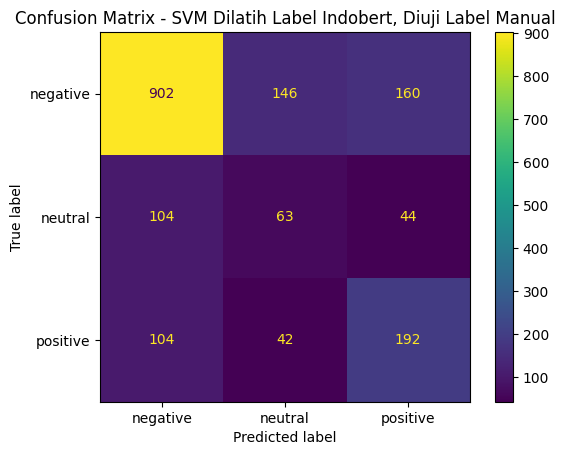

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels_order
)

cm_df = pd.DataFrame(
    cm,
    index=[f"actual_{label}" for label in labels_order],
    columns=[f"pred_{label}" for label in labels_order]
)

cm_df

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_order
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - SVM Dilatih Label Indobert, Diuji Label Manual")
plt.show()

### Analisis Eror

In [11]:
error_df = pd.DataFrame({
    'text': X_test.reset_index(drop=True),
    'label_manual': y_test.reset_index(drop=True),
    'prediksi_svm': pd.Series(y_pred)
})

error_df = error_df[
    error_df['label_manual'] != error_df['prediksi_svm']
]

print(f"Jumlah salah klasifikasi: {len(error_df)}")

error_df.head(20)

Jumlah salah klasifikasi: 600


,text,label_manual,prediksi_svm
2,bukan jokowi,positive,negative
4,memang pakai video baru tidak barni admin,negative,neutral
6,panutan iq,neutral,negative
14,harum nama bangsa,neutral,negative
17,video lucu,positive,neutral
20,terus doa paus apa pak lihat foto bpak doa,negative,neutral
22,mau reuni kali hari kaya orang makan tidak yak...,neutral,negative
26,tamak,negative,positive
28,ijazah endi mulmulanakmu sis,negative,positive
29,ayo tunjuk ijazah asli kau,neutral,negative


### Mengidentifikasi pola kesalahan klasifikasi antar kelas sentimen

In [12]:
error_df['jenis_error'] = (
    error_df['label_manual']
    + ' → ' +
    error_df['prediksi_svm']
)

error_summary = error_df['jenis_error'].value_counts()

print(error_summary)

jenis_error
negative → positive    160
negative → neutral     146
positive → negative    104
neutral → negative     104
neutral → positive      44
positive → neutral      42
Name: count, dtype: int64


### Evaluasi stabilitas model menggunakan 5-Fold Cross Validation


In [13]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = cross_validate(
    svm_indobert_model,
    X,
    y_indobert,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("HASIL 5-FOLD CROSS VALIDATION")
print("=" * 70)

print(
    f"Accuracy      : "
    f"{cv_results['test_accuracy'].mean():.4f} ± "
    f"{cv_results['test_accuracy'].std():.4f}"
)

print(
    f"Macro F1      : "
    f"{cv_results['test_f1_macro'].mean():.4f} ± "
    f"{cv_results['test_f1_macro'].std():.4f}"
)

print(
    f"Weighted F1   : "
    f"{cv_results['test_f1_weighted'].mean():.4f} ± "
    f"{cv_results['test_f1_weighted'].std():.4f}"
)

HASIL 5-FOLD CROSS VALIDATION
Accuracy      : 0.7600 ± 0.0086
Macro F1      : 0.6880 ± 0.0148
Weighted F1   : 0.7568 ± 0.0094


In [45]:
cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Macro_F1": cv_results["test_f1_macro"],
    "Weighted_F1": cv_results["test_f1_weighted"]
})

cv_df

,Fold,Accuracy,Macro_F1,Weighted_F1
0,1,0.763233,0.687896,0.758373
1,2,0.746158,0.665159,0.742233
2,3,0.754696,0.680117,0.750853
3,4,0.766079,0.699607,0.763275
4,5,0.769932,0.707228,0.769153
